In [1]:
!pip install ultralytics ensemble-boxes
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 117.0 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10


In [2]:
from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
import numpy as np
import glob, os

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="API-KEY")
project = rf.workspace("WORKSPACE_NAME").project("PROJECT_NAME")
version = project.version(19)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Secret1-19 in yolov11:: 100%|██████████| 2290/2290 [00:00<00:00, 9662.74it/s]


# **YOLOv11n**

In [6]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = "/content/Secret1-19/data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolo11n.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="runs/fish_yolo11n",
    name="exp2",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Secret1-19/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ef60d6962d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,582,542 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 681.4±289.9 MB/s, size: 22.5 KB)
val: Scanning /content/Secret1-19/valid/labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 386.4Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.8it/s 3.4s
                   all        206        221      0.993      0.988      0.994      0.826
          O.celebensis        160        173      0.993      0.977      0.994      0.842
           O.javanicus         46         48      0.994          1      0.995      0.809
Speed: 1.2ms preprocess, 6.7ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/runs/detect/val10

🔹 Evaluation Metrics:
mAP50:     0.9944
mAP50-95:  0.8256
Precision: 0.9933
Recall:    0.9884


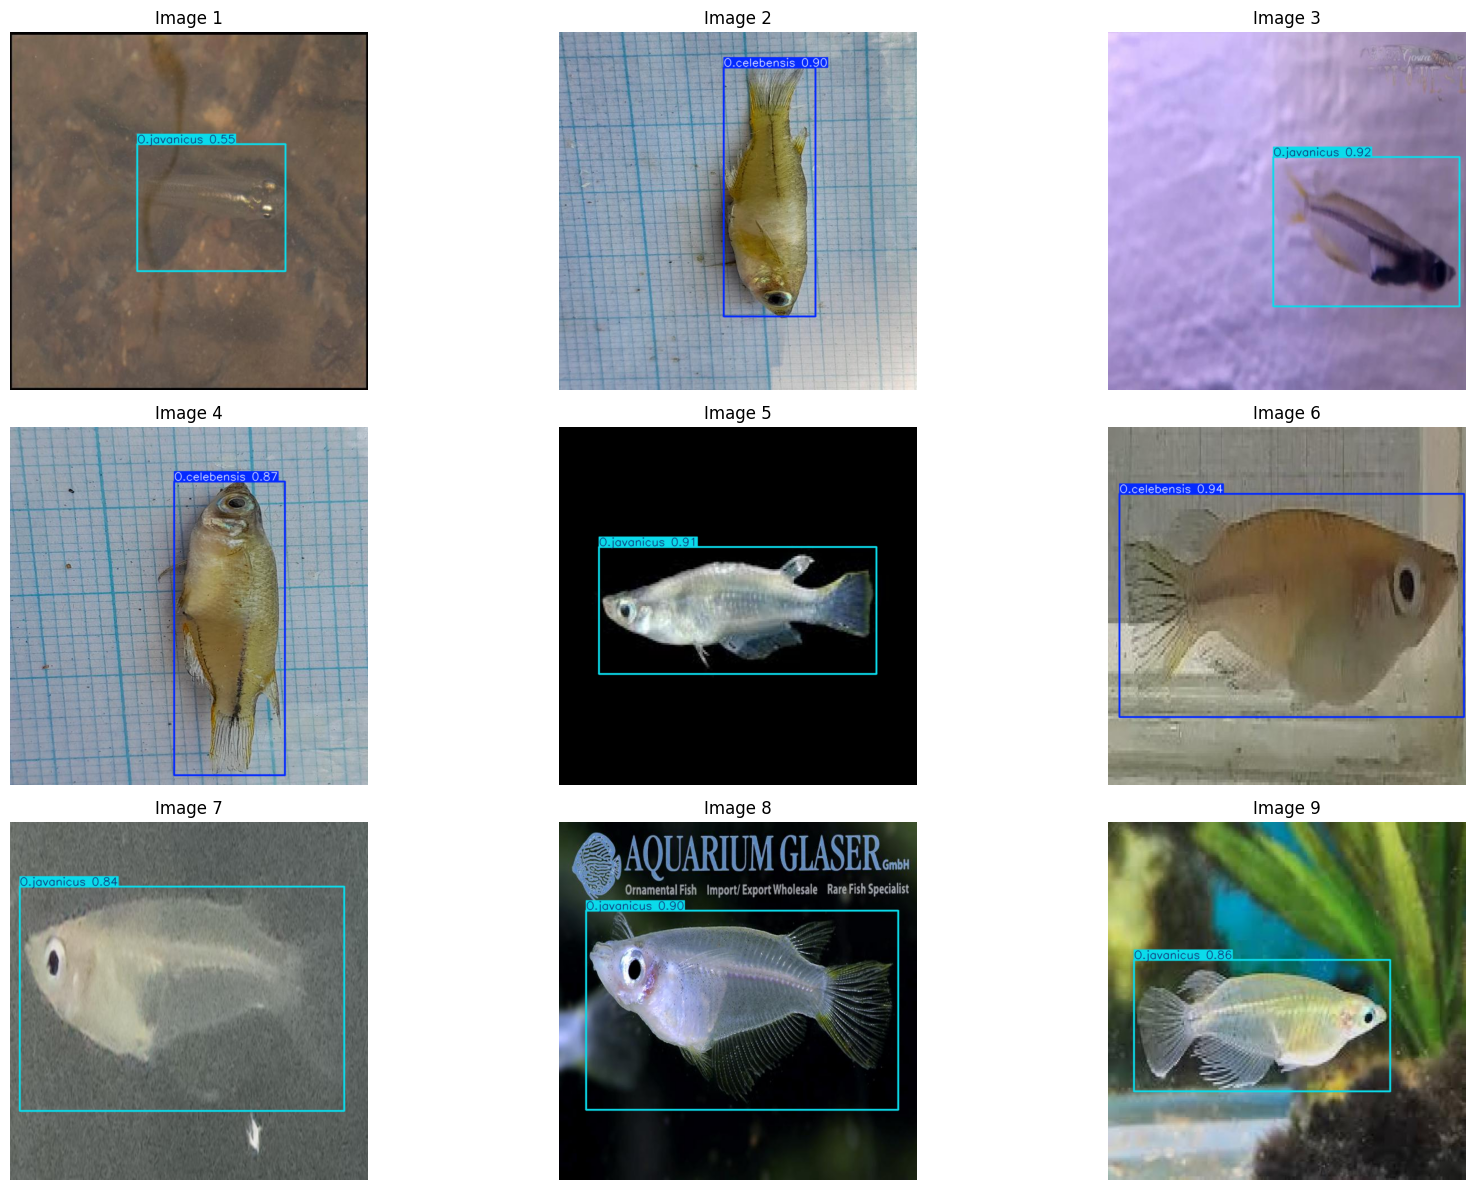

In [20]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("runs/fish_yolo11n/exp2/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob("/content/Secret1-19/test/images/*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="runs/fish_yolo11n", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:
import shutil

# Folder you want to zip
folder_path = "/content/runs/fish_yolo11n"

# Output zip file (without .zip in the name)
shutil.make_archive("yolo11n", "zip", folder_path)

'/content/yolo11n.zip'

In [9]:
from google.colab import files
files.download("/content/yolo11n.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **YOLOv10n**

In [ ]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = "/content/Secret1-19/data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov10n.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="The top canapper with. Yeah.runs/fish_yolo10n",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Secret1-19/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=1

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ef61648db80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 102 layers, 2,265,558 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1436.7±537.0 MB/s, size: 44.5 KB)
val: Scanning /content/Secret1-19/valid/labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 318.1Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.0it/s 3.3s
                   all        206        221      0.966      0.955       0.99      0.805
          O.celebensis        160        173      0.975       0.91      0.985      0.807
           O.javanicus         46         48      0.957          1      0.995      0.804
Speed: 2.5ms preprocess, 5.4ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/runs/detect/val9

🔹 Evaluation Metrics:
mAP50:     0.9898
mAP50-95:  0.8051
Precision: 0.9661
Recall:    0.9551

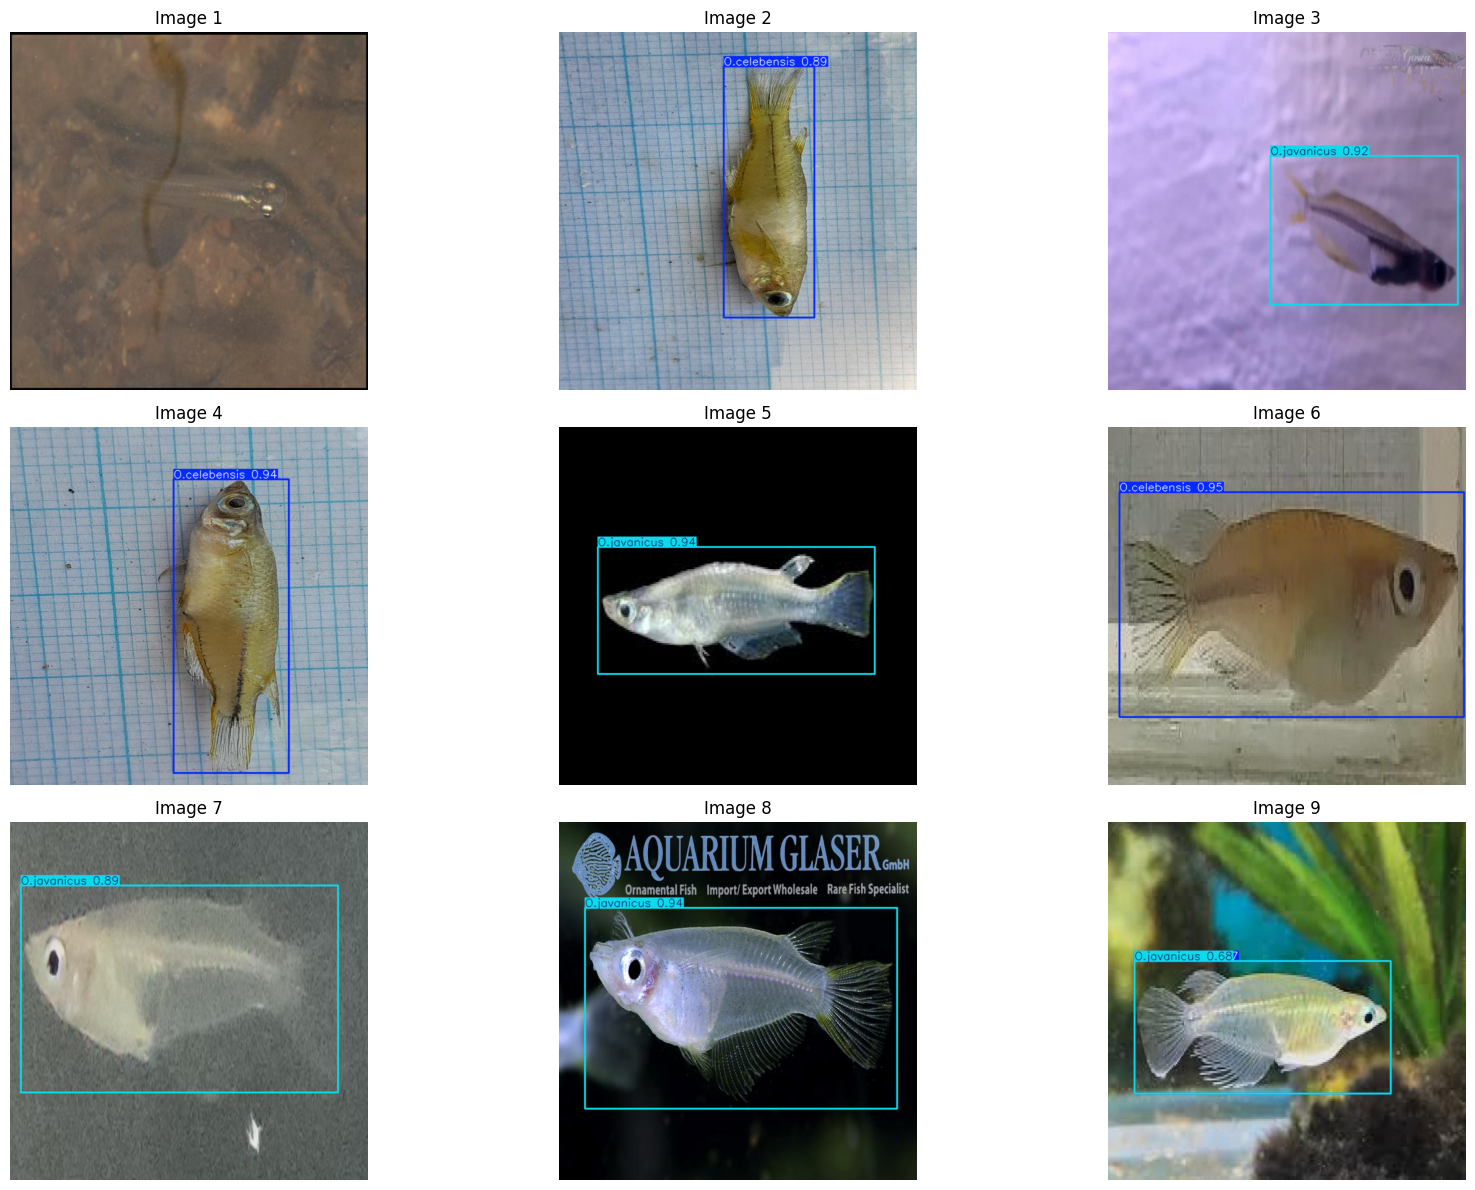

In [19]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("runs/fish_yolo10n/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob("/content/Secret1-19/test/images/*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="runs/fish_yolo10n", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [27]:
import shutil

# Folder you want to zip
folder_path = "/content/runs/fish_yolo10n"

# Output zip file (without .zip in the name)
shutil.make_archive("yolo10n", "zip", folder_path)

'/content/yolo10n.zip'

In [28]:
from google.colab import files
files.download("/content/yolo10n.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **YOLOv9n**

In [25]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = "/content/Secret1-19/data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov9t.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="runs/fish_yolo9t",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Secret1-19/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9t.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ef61b6ccd40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv9t summary (fused): 197 layers, 1,971,174 parameters, 0 gradients, 7.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1616.7±377.6 MB/s, size: 44.5 KB)
val: Scanning /content/Secret1-19/valid/labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 264.5Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.8it/s 3.4s
                   all        206        221       0.99      0.988      0.994      0.829
          O.celebensis        160        173      0.987      0.977      0.993      0.836
           O.javanicus         46         48      0.992          1      0.995      0.821
Speed: 2.0ms preprocess, 6.4ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/runs/detect/val11

🔹 Evaluation Metrics:
mAP50:     0.9940
mAP50-95:  0.8288
Precision: 0.9895
Recall:    0.9884

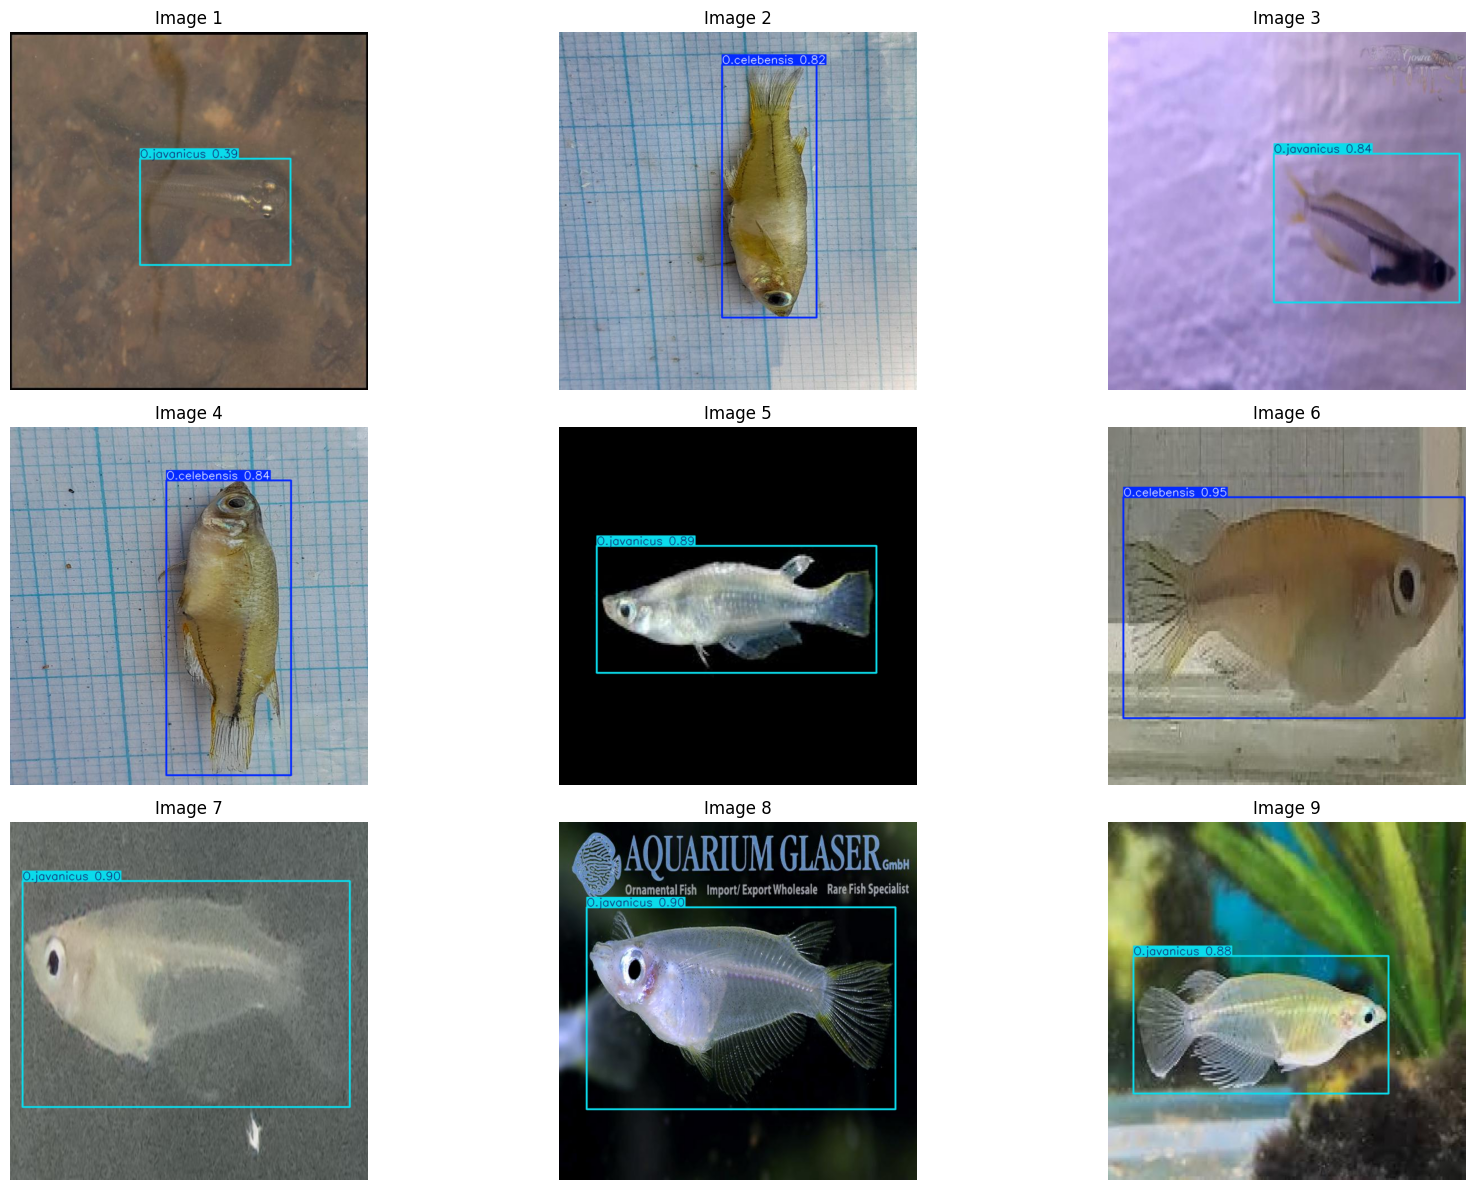

In [26]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("runs/fish_yolo9t/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob("/content/Secret1-19/test/images/*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="runs/fish_yolo9t", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [29]:
import shutil

# Folder you want to zip
folder_path = "/content/runs/fish_yolo9t"

# Output zip file (without .zip in the name)
shutil.make_archive("yolo9t", "zip", folder_path)

'/content/yolo9t.zip'

In [30]:
from google.colab import files
files.download("/content/yolo9t.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **YOLOv8n**

In [31]:
from ultralytics import YOLO

# Dataset YAML file
DATA_YAML = "/content/Secret1-19/data.yaml"

# Load a pretrained YOLOv11 model (small variant, can be m/l/x)
model = YOLO("yolov8n.pt")

# Train the model (checkpoints auto-saved in runs/)
model.train(
    data=DATA_YAML,           # YAML must define train/val paths
    epochs=50,                # increase if needed
    imgsz=640,                # image size
    project="runs/fish_yolo8n",
    name="exp1",
    exist_ok=True,            # overwrite if exists
    save=True,                # ensure checkpoints are saved
    save_period=5             # save every 5 epochs (in addition to best.pt & last.pt)
)

# Resume training from the last checkpoint
# model = YOLO("runs/fish_yolo11/exp1/weights/last.pt")
# model.train(resume=True)


Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Secret1-19/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ef60d73c380>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Ultralytics 8.3.197 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1548.2±476.7 MB/s, size: 44.5 KB)
val: Scanning /content/Secret1-19/valid/labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 256.3Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.8it/s 3.4s
                   all        206        221      0.979      0.983      0.991      0.805
          O.celebensis        160        173      0.978      0.971      0.988      0.812
           O.javanicus         46         48       0.98      0.996      0.995      0.798
Speed: 3.8ms preprocess, 4.9ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/runs/detect/val12

🔹 Evaluation Metrics:
mAP50:     0.9913
mAP50-95:  0.8050
Precision: 0.9789
Recall:    0.9835
Ac

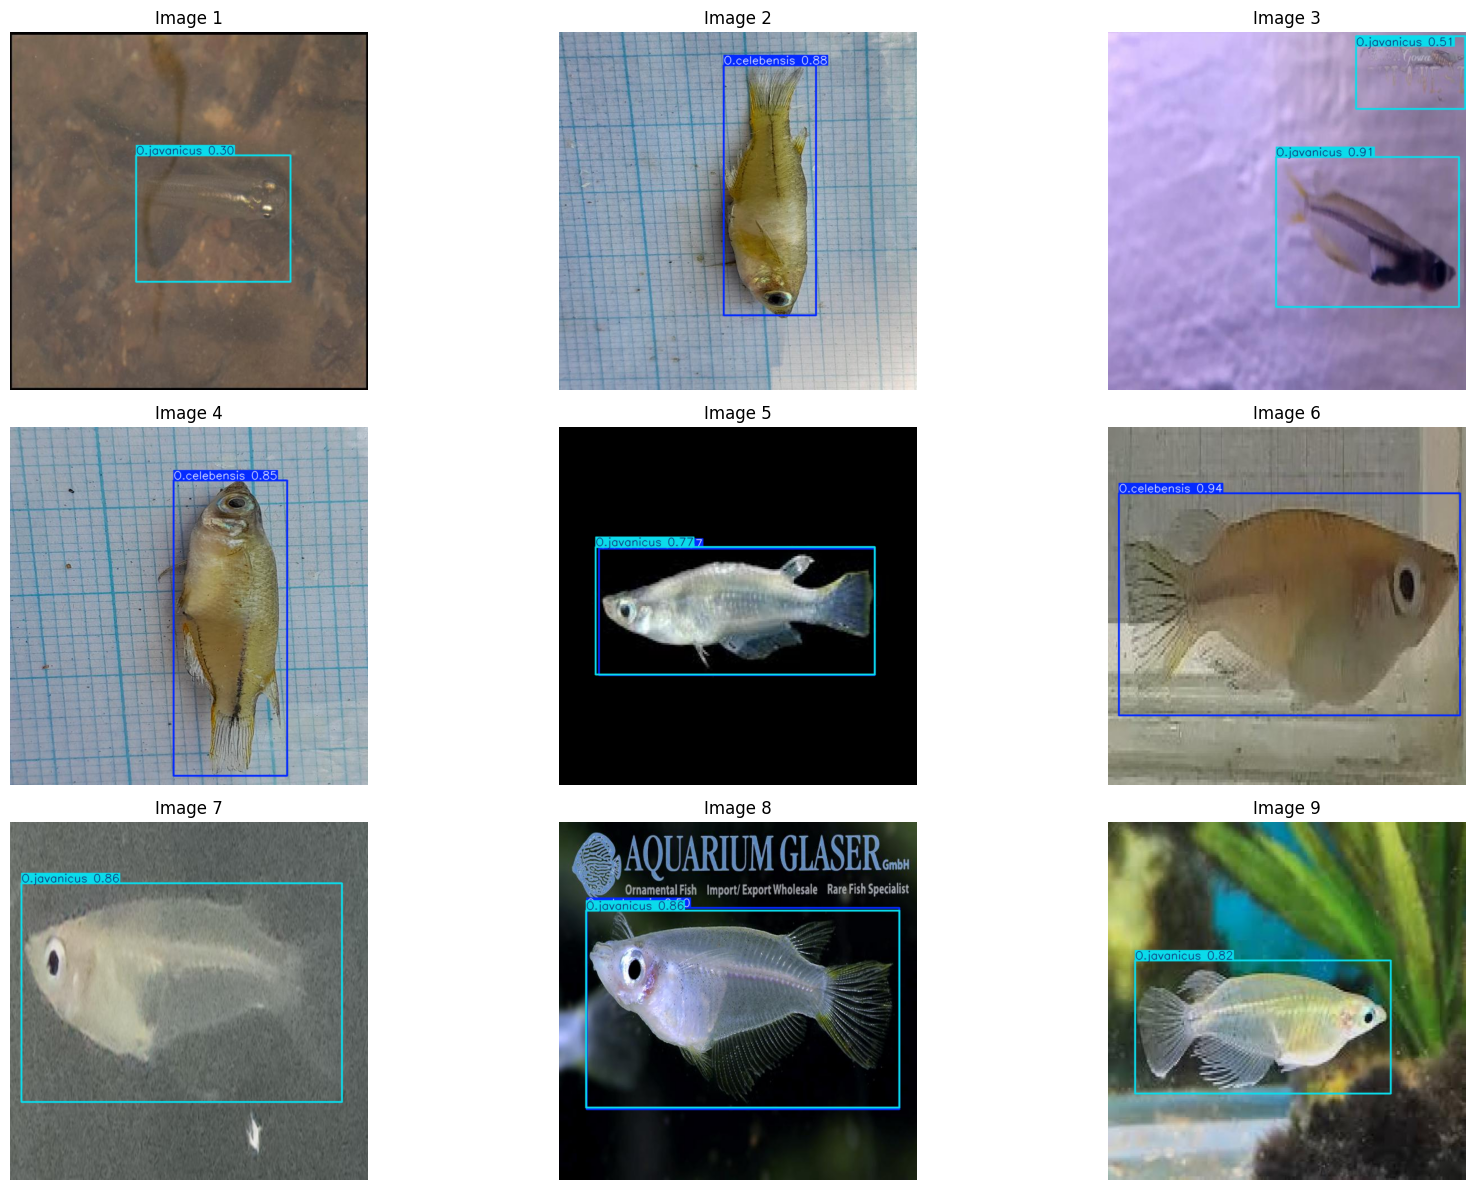

In [32]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob

# Load trained model
model = YOLO("runs/fish_yolo8n/exp1/weights/best.pt")

# --------------------------------------------------
# 1. Evaluate the model (on validation set from data.yaml)
# --------------------------------------------------
metrics = model.val()  # runs evaluation

print("\n🔹 Evaluation Metrics:")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"Accuracy:  {(metrics.box.mp * metrics.box.mr):.4f}")  # rough F1-like accuracy

# --------------------------------------------------
# 2. Predict on multiple test images
# --------------------------------------------------
test_images = glob.glob("/content/Secret1-19/test/images/*.jpg")[:9]  # 9 images

results = model.predict(test_images, conf=0.25, save=True, project="runs/fish_yolo8n", name="predictions")

# --------------------------------------------------
# 3. Visualize predictions (3x3 grid)
# --------------------------------------------------
plt.figure(figsize=(18, 12))

for i, r in enumerate(results):
    annotated_img = r.plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i+1)
    plt.imshow(annotated_img)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [36]:
import shutil

# Folder you want to zip
folder_path = "/content/runs/fish_yolo8n"

# Output zip file (without .zip in the name)
shutil.make_archive("yolo8n", "zip", folder_path)

'/content/yolo8n.zip'

In [37]:
from google.colab import files
files.download("/content/yolo8n.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# import os
# import glob
# import shutil
# from sklearn.model_selection import KFold
# from ultralytics import YOLO

# # Dataset YAML file path
# DATA_YAML = "/content/Secret1-7/data.yaml"
# NUM_FOLDS = 5

# # All images
# all_images = glob.glob("/content/Secret1-7/train/images/*.jpg")

# kf = KFold(n_splits=NUM_FOLDS, shuffle=True, random_state=42)

# for fold, (train_idx, val_idx) in enumerate(kf.split(all_images)):
#     print(f"\n🔹 Training Fold {fold+1}/{NUM_FOLDS}")

#     # Create fold directories
#     fold_dir = f"/content/datasets/fish_folds/fold{fold}"
#     for sub in ["images/train", "labels/train", "images/val", "labels/val"]:
#         os.makedirs(os.path.join(fold_dir, sub), exist_ok=True)

#     # Copy train set
#     for idx in train_idx:
#         img = all_images[idx]
#         lbl = img.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

#         shutil.copy(img, os.path.join(fold_dir, "images/train"))
#         if os.path.exists(lbl):
#             shutil.copy(lbl, os.path.join(fold_dir, "labels/train"))
#         else:
#             print(f"⚠️ Missing label for {img}, skipping...")

#     # Copy val set
#     for idx in val_idx:
#         img = all_images[idx]
#         lbl = img.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

#         shutil.copy(img, os.path.join(fold_dir, "images/val"))
#         if os.path.exists(lbl):
#             shutil.copy(lbl, os.path.join(fold_dir, "labels/val"))
#         else:
#             print(f"⚠️ Missing label for {img}, skipping...")

#     # Train YOLOv11 model
#     model = YOLO("yolo11s.pt")   # change to yolo11m/l/x if needed
#     model.train(
#         data=DATA_YAML,   # ⚠️ you might need to update yaml paths per fold
#         epochs=50,
#         imgsz=640,
#         project="runs/fish_yolo11_cv",
#         name=f"fold{fold}",
#         exist_ok=True
#     )



🔹 Training Fold 1/5
Ultralytics 8.3.195 🚀 Python-3.12.11 torch-2.8.0+cu126 CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Secret1-7/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=fold0, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True,

KeyboardInterrupt: 

In [ ]:
from ultralytics import YOLO

# 🔹 Load your single trained YOLOv11 model
model = YOLO("runs/fish_yolo11/exp1/weights/best.pt")

# 🔹 Example: single image to test
test_image = "/content/Secret1-7/test/images/O_Javanicus-001-002-Irma_Andriani-17082023_jpg.rf.957caecd28a28752e722c101b2b16b54.jpg"

# 🔹 Run prediction
results = model.predict(test_image, conf=0.25, verbose=False)[0]

# Extract boxes, scores, labels
boxes = results.boxes.xyxy.cpu().numpy().tolist()
confs = results.boxes.conf.cpu().numpy().tolist()
cls = results.boxes.cls.cpu().numpy().astype(int).tolist()

# Normalize coords [0,1] if you want to later use WBF (though with 1 model, not needed)
h, w = results.orig_shape
boxes_normalized = [[x1/w, y1/h, x2/w, y2/h] for x1, y1, x2, y2 in boxes]

print("🔹 Boxes:", boxes_normalized)
print("🔹 Confidences:", confs)
print("🔹 Classes:", cls)

# (Optional) Visualize prediction
results.show()

In [ ]:
# # WBF
# boxes, scores, labels = weighted_boxes_fusion(
#     predictions, scores, labels,
#     iou_thr=0.5, skip_box_thr=0.0001
# )

# # Convert back to pixel coords
# h, w = results.orig_shape
# boxes = [[int(x1*w), int(y1*h), int(x2*w), int(y2*h)] for x1,y1,x2,y2 in boxes]

# # Print results
# for b, s, l in zip(boxes, scores, labels):
#     print(f"Class {l}, Conf {s:.2f}, Box {b}")


In [ ]:
# import cv2

# img = cv2.imread(test_image)

# for b, s, l in zip(boxes, scores, labels):
#     x1,y1,x2,y2 = b
#     cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
#     cv2.putText(img, f"cls {l} {s:.2f}", (x1, y1-5),
#                 cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

# cv2.imwrite("ensemble_result.jpg", img)
